## 1. Import Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

## 2. Get the Data

In [4]:
# read the csv file into a dataframe
ad_data = pd.read_csv('advertising(in).csv')

# Exploratory Data Analysis

In [5]:
ad_data.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,3/27/2016 0:53,0
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,4/4/2016 1:39,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,3/13/2016 20:35,0
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,1/10/2016 2:31,0
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,6/3/2016 3:36,0


In [6]:
ad_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Daily Time Spent on Site  1000 non-null   float64
 1   Age                       1000 non-null   int64  
 2   Area Income               1000 non-null   float64
 3   Daily Internet Usage      1000 non-null   float64
 4   Ad Topic Line             1000 non-null   object 
 5   City                      1000 non-null   object 
 6   Male                      1000 non-null   int64  
 7   Country                   1000 non-null   object 
 8   Timestamp                 1000 non-null   object 
 9   Clicked on Ad             1000 non-null   int64  
dtypes: float64(3), int64(3), object(4)
memory usage: 78.3+ KB


In [7]:
ad_data.describe()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Clicked on Ad
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,65.000200,36.009000,55000.000080,180.000100,0.481000,0.50000
std,15.853615,8.785562,13414.634022,43.902339,0.499889,0.50025
min,32.600000,19.000000,13996.500000,104.780000,0.000000,0.00000
25%,51.360000,29.000000,47031.802500,138.830000,0.000000,0.00000
50%,68.215000,35.000000,57012.300000,183.130000,0.000000,0.50000
75%,78.547500,42.000000,65470.635000,218.792500,1.000000,1.00000
max,91.430000,61.000000,79484.800000,269.960000,1.000000,1.00000


### Missing data

In [8]:
ad_data.isnull().sum()

,0
Daily Time Spent on Site,0
Age,0
Area Income,0
Daily Internet Usage,0
Ad Topic Line,0
City,0
Male,0
Country,0
Timestamp,0
Clicked on Ad,0


<Axes: >

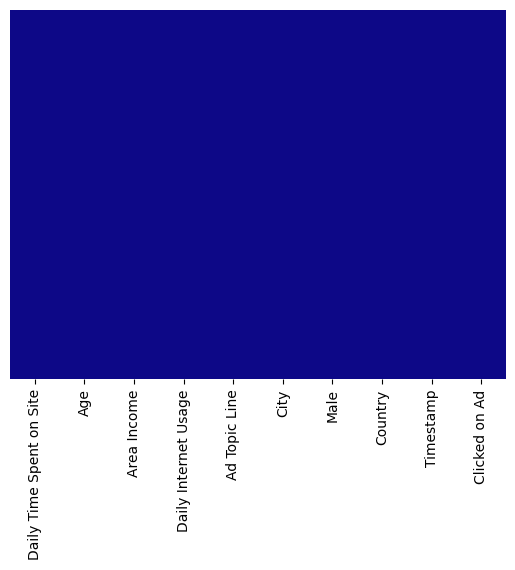

In [9]:
sns.heatmap(ad_data.isnull(), yticklabels=False, cbar=False, cmap='plasma')

### Plots

In [10]:
sns.set_style('darkgrid')

**How many users clicked on the ad and how many did not?**

<Axes: xlabel='Clicked on Ad', ylabel='count'>

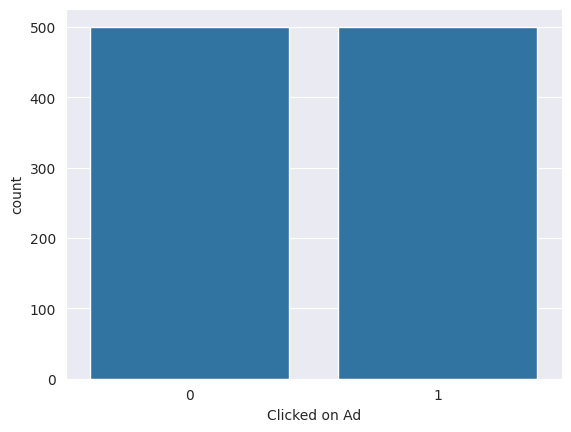

In [11]:
sns.countplot(x='Clicked on Ad', data=ad_data)

The data is balanced: 500 users clicked and 500 did not.

**Clicked on Ad by gender**

<Axes: xlabel='Clicked on Ad', ylabel='count'>

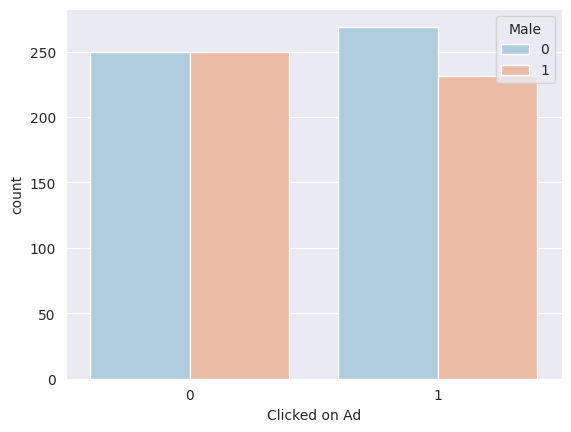

In [12]:
sns.countplot(x='Clicked on Ad', hue='Male', data=ad_data, palette='RdBu_r')

**Age of the users**

Text(0.5, 0, 'Age')

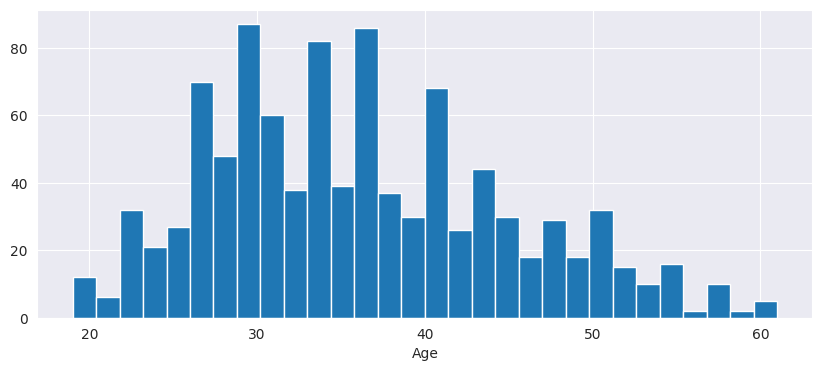

In [13]:
ad_data['Age'].hist(bins=30, figsize=(10,4))
plt.xlabel('Age')

Most users are between about 25 and 45 years old.

**Area Income**

Text(0.5, 0, 'Area Income')

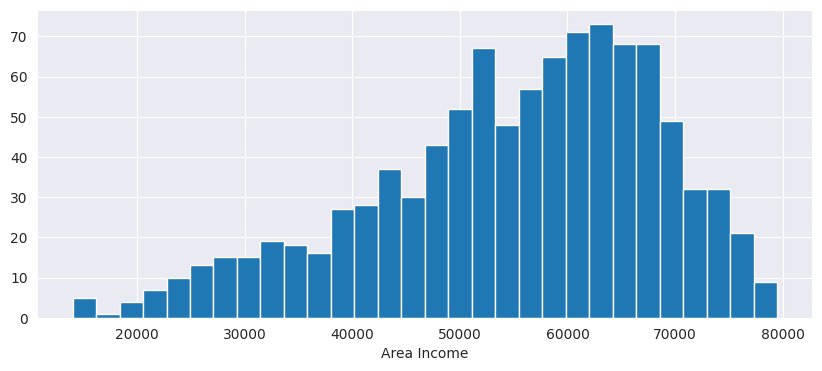

In [14]:
ad_data['Area Income'].hist(bins=30, figsize=(10,4))
plt.xlabel('Area Income')

<Axes: >

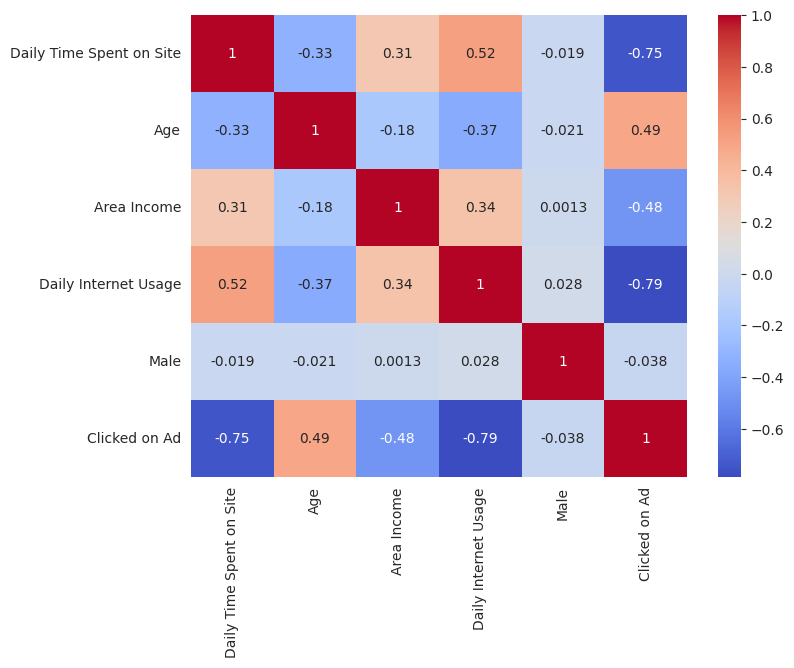

In [15]:
plt.figure(figsize=(8,6))
sns.heatmap(ad_data.corr(numeric_only=True), annot=True, cmap='coolwarm')

`Daily Internet Usage` (-0.79) and `Daily Time Spent on Site` (-0.75) have the strongest negative correlation with `Clicked on Ad`. `Area Income` is also negative (-0.48) and `Age` is positive (0.49, older users click more). `Male` has almost no correlation with clicking (-0.04).

# Data Cleaning


In [16]:
ad_data[['Ad Topic Line', 'City', 'Country', 'Timestamp']].nunique()

,0
Ad Topic Line,1000
City,969
Country,237
Timestamp,997


* `Ad Topic Line` has 1000 different values (every row is different)
* `City` has 969 different values
* `Timestamp` has 997 different values
* `Country` has 237 different values
To keep the model simple I will drop 'Ad Topic Line', 'City', 'Country', 'Timestamp'.

In [17]:
ad_data.drop(['Ad Topic Line', 'City', 'Country', 'Timestamp'], axis=1, inplace=True)

In [18]:
ad_data.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Clicked on Ad
0,68.95,35,61833.90,256.09,0,0
1,80.23,31,68441.85,193.77,1,0
2,69.47,26,59785.94,236.50,0,0
3,74.15,29,54806.18,245.89,1,0
4,68.37,35,73889.99,225.58,0,0


# Train Test Split

In [19]:
X = ad_data.drop('Clicked on Ad', axis=1)
y = ad_data['Clicked on Ad']

In [20]:
X.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male
0,68.95,35,61833.90,256.09,0
1,80.23,31,68441.85,193.77,1
2,69.47,26,59785.94,236.50,0
3,74.15,29,54806.18,245.89,1
4,68.37,35,73889.99,225.58,0


In [21]:
from sklearn.model_selection import train_test_split

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

In [23]:
print(X_train.shape)
print(X_test.shape)

(700, 5)
(300, 5)


# Training and Predicting

In [24]:
from sklearn.linear_model import LogisticRegression

In [25]:
logmodel = LogisticRegression(solver='liblinear', max_iter=100)

In [26]:
logmodel.fit(X_train, y_train)

LogisticRegression(solver='liblinear')

In [27]:
predictions = logmodel.predict(X_test)

# Evaluation

In [28]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [29]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.91      0.95      0.93       157
           1       0.94      0.90      0.92       143

    accuracy                           0.92       300
   macro avg       0.92      0.92      0.92       300
weighted avg       0.92      0.92      0.92       300



In [30]:
confusion_matrix(y_test, predictions)

array([[149,   8],
       [ 15, 128]])

Text(50.722222222222214, 0.5, 'Actual')

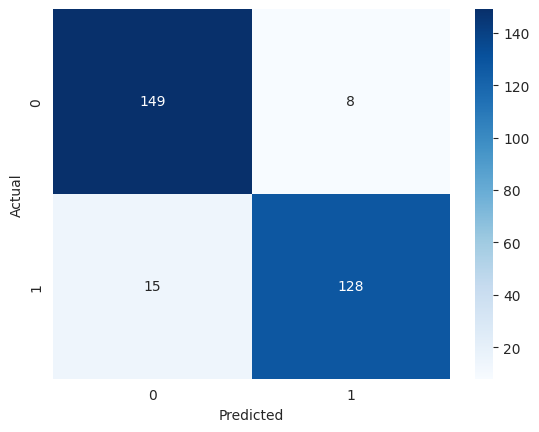

In [31]:
sns.heatmap(confusion_matrix(y_test, predictions), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')

In [32]:
print('Accuracy:', accuracy_score(y_test, predictions))

Accuracy: 0.9233333333333333
